# Data Visualization — Quiz (Lectures 1–7)

**Time:** 90 minutes 
**Tools:** Plotly only (`plotly.express` first, then `update_traces` / `update_layout` / `update_xaxes` / `update_yaxes`)

**Your task:** answer each analytical question with **one polished, explanatory visualization**. For every question **you decide which chart type fits best** — and justify the choice in one or two sentences.

**Every figure must have:**
1. An **insight title** that states the finding, not just the variables
2. `template='plotly_white'` and a decluttered layout (no unnecessary gridlines, legends or axis titles)
3. A **CVD-safe palette** — no red/green; grey for context + one accent colour where it helps
4. Colour that **encodes meaning**, not decoration
5. Direct labels or annotations where they help the reader

**Chart types covered in the course** — choose from these:
line chart · sorted bar chart · stacked / 100% stacked bar chart · scatter plot · bubble chart · histogram · box plot · violin plot · choropleth map · treemap

> 💡 Each question has one chart type that fits it best, and the questions together cover most of the list above. If two of your answers use the same chart type, check the question again.


**Submit:** this notebook pushed to your personal repo as `quiz/dataviz_quiz.ipynb`

## The dataset — World Population 1970–2022

**Source:** [World Population Dataset](https://www.kaggle.com/datasets/iamsouravbanerjee/world-population-dataset) on Kaggle, compiled from Worldometer (UN World Population Prospects estimates). **234 rows × 16 columns — one row per country or territory, no missing values.**

| Column | Type | Description |
|---|---|---|
| `Country`, `Capital` | categorical | Country / territory and its capital |
| `Continent` | categorical | Africa, Asia, Europe, North America, Oceania, South America |
| `CCA3` | spatial | ISO-3 country code — use with `locationmode='ISO-3'` |
| `1970 Population` … `2022 Population` | temporal | Population in 1970, 1980, 1990, 2000, 2010, 2015, 2020, 2022 |
| `Area` | numerical | Land area in km² |
| `Density` | numerical | People per km² (2022) |
| `World share (%)` | numerical | Share of world population in 2022 |
| `Rank` | numerical | Rank by 2022 population |

**The next setup cell also gives you `df_long` — the same data in **tidy (long) format** with one row per country per year. Use `df` for one-year questions and `df_long` for questions about change over time**

In [1]:
import pandas as pd
import plotly.express as px
import numpy as np

df = pd.read_csv('world_population.csv')

# Shorter column names
df = df.rename(columns={'Country/Territory': 'Country', 'Area (km²)': 'Area',
                        'Density (per km²)': 'Density', 'World Population Percentage': 'World share (%)'})

# Tidy (long) version: one row per country per year
year_cols = [c for c in df.columns if c.endswith('Population')]
df_long = df.melt(id_vars=['CCA3', 'Country', 'Continent'], value_vars=year_cols,
                  var_name='Year', value_name='Population')

df_long['Year'] = df_long['Year'].str[:4].astype(int)     # '2022 Population' → 2022

print(df.shape, df_long.shape)


(234, 16) (1872, 5)


---
## Q1 — Which continent is growing fastest?

How has the population of each continent **grown since 1970, relative to its 1970 size** — and which continent is growing fastest?


**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

*YOUR ANSWER HERE* :- : I use a line chart because the question asks how a measure changes over time. Each continent's population is first summed across its countries for each year, then indexed to 1970 = 100. This makes the lines comparable as relative growth, rather than allowing the largest continent to dominate because of its starting population. The line with the highest 2022 index represents the fastest growth.

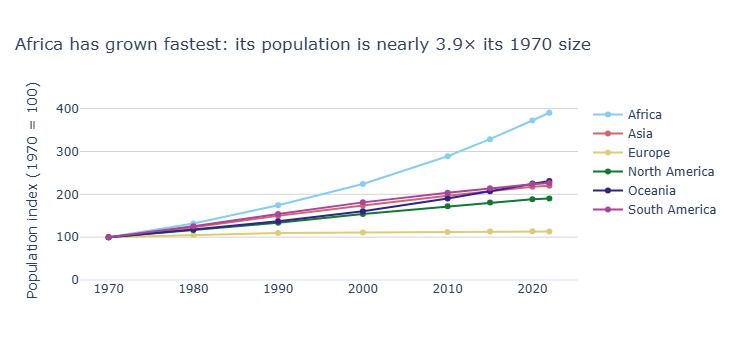

In [2]:
# Q1
# YOUR CODE HERE
# Q1 — relative population growth by continent
# Aggregate country populations within each continent and year.
continent_year = (
    df_long.groupby(['Continent', 'Year'], as_index=False)['Population']
    .sum()
)

# Index each continent to its own 1970 population (1970 = 100).
base_1970 = (
    continent_year.loc[continent_year['Year'] == 1970,
                       ['Continent', 'Population']]
    .rename(columns={'Population': 'Population_1970'})
)
continent_year = continent_year.merge(base_1970, on='Continent')
continent_year['Index (1970 = 100)'] = (
    continent_year['Population'] / continent_year['Population_1970'] * 100
)

fig = px.line(
    continent_year, x='Year', y='Index (1970 = 100)',
    color='Continent', markers=True,
    title='Africa has grown fastest: its population is nearly 3.9× its 1970 size',
    labels={'Year': 'Year', 'Index (1970 = 100)': 'Population index (1970 = 100)',
            'Continent': 'Continent'},
    color_discrete_sequence=px.colors.qualitative.Safe
)
fig.update_layout(
    template='plotly_white',
    legend_title_text='',
    yaxis_title='Population index (1970 = 100)',
    xaxis_title='',
    title_x=0.02
)
fig.update_xaxes(showgrid=False, dtick=10)
fig.update_yaxes(showgrid=True, gridcolor='lightgrey', rangemode='tozero')
fig.show()

# Africa is the fastest-growing continent in relative terms:
# 2022 / 1970 is approximately 3.90, or an index near 390.

---
## Q2 — Which countries added the most people?

Which **15 countries added the most people** between 1970 and 2022 — and how many of them are in **Africa**?

**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

*YOUR ANSWER HERE*:- I use a sorted horizontal bar chart because the task is to rank 15 countries by the number of additional people. Sorting from largest to smallest makes comparisons and the cut-off easy to read; continent colour identifies which of the leading countries are in Africa.

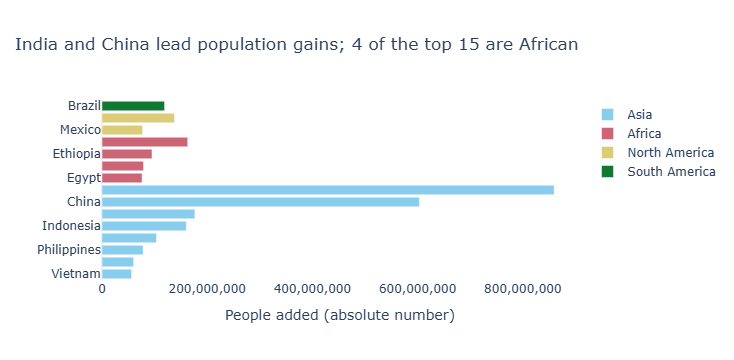

African countries in the top 15: 4
      Country     Continent  People added (1970–2022)
        India          Asia                 859671872
        China          Asia                 603352887
     Pakistan          Asia                 176533990
      Nigeria        Africa                 162971948
    Indonesia          Asia                 160272945
United States North America                 137961517
       Brazil South America                 118943623
   Bangladesh          Asia                 103644512
     Ethiopia        Africa                  95071678
     DR Congo        Africa                  78858479
  Philippines          Asia                  78123423
       Mexico North America                  77214819
        Egypt        Africa                  76208117
         Iran          Asia                  60100865
      Vietnam          Asia                  56258007


In [3]:
# Q2
# YOUR CODE HERE

# Q2 — 15 countries with the largest absolute population increase
df_q2 = df.copy()
df_q2['People added (1970–2022)'] = (
    df_q2['2022 Population'] - df_q2['1970 Population']
)
top15 = df_q2.nlargest(15, 'People added (1970–2022)').sort_values(
    'People added (1970–2022)', ascending=True
)
africa_count = (top15['Continent'] == 'Africa').sum()

fig = px.bar(
    top15, x='People added (1970–2022)', y='Country',
    orientation='h', color='Continent',
    title=f'India and China lead population gains; {africa_count} of the top 15 are African',
    labels={'People added (1970–2022)': 'Additional people, 1970–2022',
            'Country': '', 'Continent': 'Continent'},
    color_discrete_sequence=px.colors.qualitative.Safe
)
fig.update_layout(template='plotly_white', title_x=0.02,
                  xaxis_title='People added (absolute number)', yaxis_title='',
                  legend_title_text='')
fig.update_xaxes(showgrid=False, tickformat=',')
fig.update_yaxes(showgrid=False)
fig.show()

print(f'African countries in the top 15: {africa_count}')
print(top15.sort_values('People added (1970–2022)', ascending=False)[
    ['Country', 'Continent', 'People added (1970–2022)']
].to_string(index=False))

---
## Q3 — Do bigger countries have more people?

Is there a relationship between a country's **land area** and its **2022 population** — does it differ by **continent**, and which countries clearly break the pattern?

**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

*YOUR ANSWER HERE*:-I use a bubble scatter plot because it shows the relationship between two numerical variables (land area and population) while also allowing continent to be compared. Logarithmic axes make countries with very different sizes readable; bubble size represents population density. Labels on selected examples help identify departures from a simple area–population pattern.

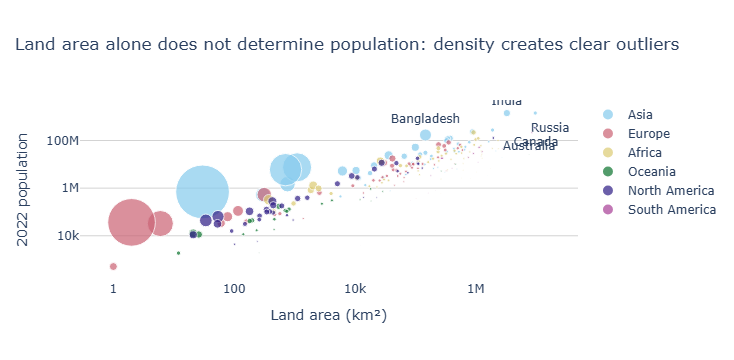

Pearson correlation (area vs 2022 population): 0.4534113215782554
Examples: India and Bangladesh have very large populations relative to area; Russia, Canada and Australia have vast areas but comparatively lower populations.


In [4]:
# Q3
# YOUR CODE HERE
# Q3 — land area versus 2022 population
# Bubble size shows density; logarithmic axes make the wide ranges readable.
# Label a few illustrative cases: densely populated India/Bangladesh and
# very large, comparatively sparsely populated Russia/Canada/Australia.
label_countries = ['India', 'Bangladesh', 'Russia', 'Canada', 'Australia']
df_q3 = df.copy()
df_q3['Label'] = np.where(df_q3['Country'].isin(label_countries),
                          df_q3['Country'], '')

fig = px.scatter(
    df_q3, x='Area', y='2022 Population',
    size='Density', size_max=38, color='Continent',
    hover_name='Country',
    hover_data={'Area': ':,', '2022 Population': ':,',
                'Density': ':.1f', 'Continent': True},
    text='Label',
    title='Land area alone does not determine population: density creates clear outliers',
    labels={'Area': 'Land area (km²)', '2022 Population': '2022 population',
            'Continent': 'Continent'},
    color_discrete_sequence=px.colors.qualitative.Safe
)
fig.update_traces(textposition='top center', marker=dict(opacity=0.72))
fig.update_layout(template='plotly_white', title_x=0.02, legend_title_text='')
fig.update_xaxes(type='log', showgrid=False)
fig.update_yaxes(type='log', showgrid=True, gridcolor='lightgrey')
fig.show()

print('Pearson correlation (area vs 2022 population):',
      df_q3['Area'].corr(df_q3['2022 Population']))
print('Examples: India and Bangladesh have very large populations relative to area; '
      'Russia, Canada and Australia have vast areas but comparatively lower populations.')

---
## Q4 — How crowded are the continents?

How does **population density vary within and across continents**? Show the spread, not just the average.

**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

*YOUR ANSWER HERE*:- I use a violin plot because the question asks for the spread of population density within and between continents, not only the mean. Each violin shows the distribution and concentration of country-level density values, while the embedded box gives a compact view of the median and interquartile range. A logarithmic density axis accommodates the highly skewed values.

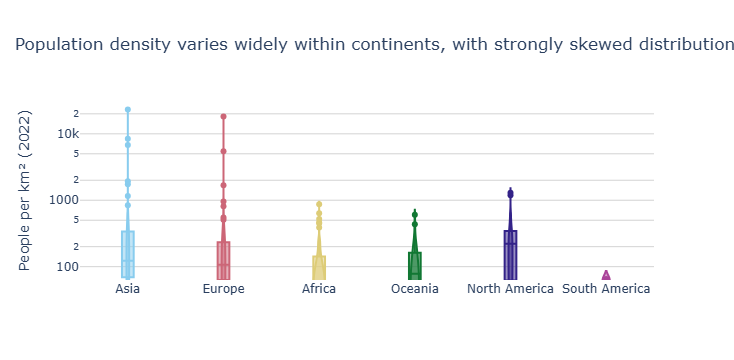

               count  median    mean  min      max
Continent                                         
Africa            57    59.7   125.0  2.2    871.9
Asia              50   123.0  1025.0  2.2  23172.3
Europe            50   106.9   663.3  3.6  18234.5
North America     40   221.4   272.8  0.0   1299.3
Oceania           23    78.2   132.5  3.4    603.2
South America     14    17.8    21.0  0.3     65.0


In [5]:
# Q4
# YOUR CODE HERE

# Q4 — distribution of country-level population density by continent
fig = px.violin(
    df, x='Continent', y='Density', color='Continent',
    box=True, points='outliers',
    title='Population density varies widely within continents, with strongly skewed distributions',
    labels={'Continent': '', 'Density': 'People per km² (2022)'},
    color_discrete_sequence=px.colors.qualitative.Safe
)
fig.update_layout(template='plotly_white', title_x=0.02,
                  showlegend=False, xaxis_title='')
fig.update_xaxes(showgrid=False)
fig.update_yaxes(type='log', showgrid=True, gridcolor='lightgrey')
fig.show()

print(df.groupby('Continent')['Density'].agg(
    ['count', 'median', 'mean', 'min', 'max']
).round(1).to_string())

---
## Q5 — Where did populations grow — and where did they shrink?

Which countries' populations **grew and which shrank between 2000 and 2022** (percentage change), and where in the world are they?

**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

*YOUR ANSWER HERE*:-I use a choropleth map because the question asks where population growth and decline occurred geographically. The country fill encodes percentage change from 2000 to 2022, so countries can be compared on a relative basis rather than by absolute population size. A diverging colour scale centred on zero distinguishes growth from shrinkage.

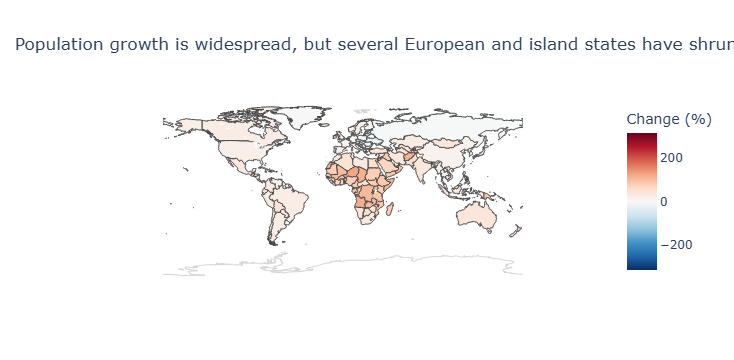

Largest percentage increases:
                 Country     Continent  Change (%)
                   Qatar          Asia       317.2
    United Arab Emirates          Asia       188.2
       Equatorial Guinea        Africa       144.5
Turks and Caicos Islands North America       143.8
                   Niger        Africa       125.5

Largest percentage decreases:
                 Country Continent  Change (%)
Northern Mariana Islands   Oceania       -38.3
          American Samoa   Oceania       -24.0
               Lithuania    Europe       -23.6
        Marshall Islands   Oceania       -23.3
                 Moldova    Europe       -23.0


In [6]:
# Q5
# YOUR CODE HERE

# Q5 — percentage population change by country, 2000–2022
df_q5 = df.copy()
df_q5['Change (%)'] = (
    (df_q5['2022 Population'] - df_q5['2000 Population'])
    / df_q5['2000 Population'] * 100
)

fig = px.choropleth(
    df_q5, locations='CCA3', locationmode='ISO-3',
    color='Change (%)', hover_name='Country',
    hover_data={'Continent': True, 'Change (%)': ':.1f',
                '2000 Population': ':,', '2022 Population': ':,'},
    color_continuous_scale='RdBu_r', color_continuous_midpoint=0,
    title='Population growth is widespread, but several European and island states have shrunk',
    labels={'Change (%)': 'Population change (%)'},
)
fig.update_layout(template='plotly_white', title_x=0.02,
                  geo=dict(showframe=False, showcoastlines=True,
                           coastlinecolor='lightgrey'),
                  coloraxis_colorbar_title='Change (%)')
fig.show()

print('Largest percentage increases:')
print(df_q5.nlargest(5, 'Change (%)')[
    ['Country', 'Continent', 'Change (%)']
].round(1).to_string(index=False))
print('\nLargest percentage decreases:')
print(df_q5.nsmallest(5, 'Change (%)')[
    ['Country', 'Continent', 'Change (%)']
].round(1).to_string(index=False))

---
## Q6 — Where do the world's 8 billion people live?

How is the **2022 world population** distributed across **continents and the countries within them**? Show both levels in one figure.

**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

*YOUR ANSWER HERE*:-I use a treemap because it can show the hierarchy of the world population in one figure: continent first, then countries within each continent. Rectangle area is proportional to 2022 population, making both the continental contribution and the largest countries immediately visible.

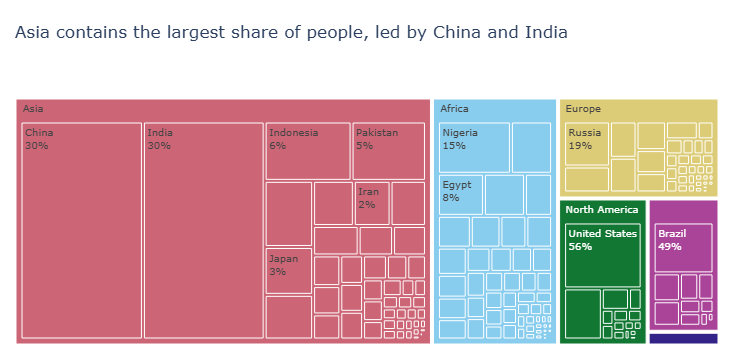

2022 population by continent:
Continent
Asia             4721383274
Africa           1426730932
Europe            743147538
North America     600296136
South America     436816608
Oceania            45038554

World total: 7,973,413,042


In [7]:
# Q6
# YOUR CODE HERE # Q6 — hierarchical distribution of 2022 world population
fig = px.treemap(
    df, path=['Continent', 'Country'],
    values='2022 Population',
    color='Continent',
    title='Asia contains the largest share of people, led by China and India',
    hover_data={'2022 Population': ':,'},
    color_discrete_sequence=px.colors.qualitative.Safe
)
fig.update_traces(
    textinfo='label+percent parent',
    hovertemplate='<b>%{label}</b><br>Population: %{value:,}<br>'
                  'Share of parent: %{percentParent:.1%}<extra></extra>'
)
fig.update_layout(template='plotly_white', title_x=0.02,
                  margin=dict(t=75, l=10, r=10, b=10),
                  uniformtext=dict(minsize=10, mode='hide'))
fig.show()

continent_totals = df.groupby('Continent')['2022 Population'].sum().sort_values(
    ascending=False
)
print('2022 population by continent:')
print(continent_totals.to_string())
print('\nWorld total:', f"{df['2022 Population'].sum():,}")

---
## Q7 — Whose share of the world is rising?

How have the shares of world population held by **Africa, Asia and Europe** changed from 1970 to 2022? Group the other three continents as `'Rest of the world'`.

**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

*YOUR ANSWER HERE*:-I use a 100% stacked bar chart because the question is about how shares change, not how absolute population totals change. Each year is normalized to 100%, and the three named continents remain separate while the other three are combined into “Rest of the world”; segment changes therefore show shifts in the composition of the world population.

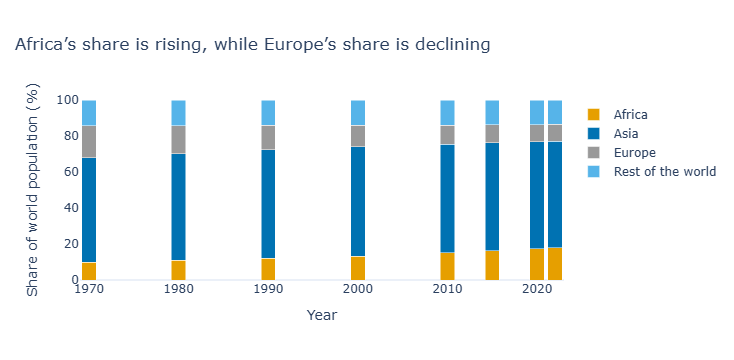

World population shares (%):
Group  Africa   Asia  Europe  Rest of the world
Year                                           
1970     9.89  58.06   17.76              14.29
1980    10.84  59.32   15.59              14.25
1990    12.01  60.41   13.55              14.02
2000    13.32  60.76   11.81              14.10
2010    15.11  60.43   10.53              13.93
2015    16.18  60.05    9.99              13.79
2020    17.36  59.48    9.51              13.65
2022    17.89  59.21    9.32              13.57

Change in share, 1970 to 2022 (percentage points):
Group
Africa               8.00
Asia                 1.15
Europe              -8.44
Rest of the world   -0.72


In [8]:
# Q7
# YOUR CODE HERE 
# Q7 — changing shares of world population, 1970–2022
# Sum country populations by continent and year, then combine the other
# three continents into one category as requested.
continent_year_q7 = (
    df_long.groupby(['Continent', 'Year'], as_index=False)['Population']
    .sum()
)
continent_year_q7['Group'] = np.where(
    continent_year_q7['Continent'].isin(['Africa', 'Asia', 'Europe']),
    continent_year_q7['Continent'], 'Rest of the world'
)
grouped = (
    continent_year_q7.groupby(['Year', 'Group'], as_index=False)['Population']
    .sum()
)
world_totals = grouped.groupby('Year')['Population'].transform('sum')
grouped['World share (%)'] = grouped['Population'] / world_totals * 100

fig = px.bar(
    grouped, x='Year', y='World share (%)', color='Group',
    title='Africa’s share is rising, while Europe’s share is declining',
    labels={'Year': 'Year', 'World share (%)': 'Share of world population (%)',
            'Group': ''},
    category_orders={'Group': ['Africa', 'Asia', 'Europe', 'Rest of the world']},
    color_discrete_map={
        'Africa': '#E69F00', 'Asia': '#0072B2',
        'Europe': '#999999', 'Rest of the world': '#56B4E9'
    }
)
fig.update_layout(template='plotly_white', title_x=0.02,
                  barmode='stack', barnorm='percent',
                  legend_title_text='')
fig.update_xaxes(showgrid=False, dtick=10)
fig.update_yaxes(showgrid=False, range=[0, 100],
                 title='Share of world population (%)')
fig.show()

share_pivot = grouped.pivot(index='Year', columns='Group',
                            values='World share (%)')
print('World population shares (%):')
print(share_pivot.round(2).to_string())
print('\nChange in share, 1970 to 2022 (percentage points):')
print((share_pivot.loc[2022] - share_pivot.loc[1970]).round(2).to_string())